## 00-EDA Exploratory Data Analysis

In this notebook, we are going to do EDA (Exploratory Data Analysis) on the train set. We would focus on the text data first.

In [129]:
# import required packages
import pandas as pd
import os
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [130]:
# labels
# AD = Alzheimer's Disease (positive class)
# CN = Cognitively Normal (negative class)

In [131]:
path_ad = "../data/Transcribed Data-2024-Feb-13/Diagnosis Training Data/ad transcribed/"
path_cn = (
    "../data/Transcribed Data-2024-Feb-13//Diagnosis Training Data/cn transcribed/"
)
mmse_scores_fname = "../data/Training Dataset/Diagnosis training data/ADReSSo21/diagnosis/train/adresso-train-mmse-scores.csv"

In [132]:
def read_data(path):
    """
    get data from "txt" files from a specified folder (ad/cn)
    returns list of text (strings)
    """
    result = []
    # get only txt files
    files = sorted([item for item in os.listdir(path) if item.endswith("txt")])

    for fname in files:
        print("Processing files =", fname)  # , end="\r")
        with open(path + fname, encoding="utf-8") as f:
            lines = f.readlines()
            print("Line len =", len(lines))  # , end="\r")
            text = "\n".join(lines)
            result.append((fname.split(".txt")[0], text))

    return result


train_data["ad"] = read_data(path_ad)
train_data["cn"] = read_data(path_cn)

Processing files = adrso024.txt
Line len = 23
Processing files = adrso025.txt
Line len = 13
Processing files = adrso027.txt
Line len = 9
Processing files = adrso028.txt
Line len = 17
Processing files = adrso031.txt
Line len = 29
Processing files = adrso032.txt
Line len = 5
Processing files = adrso033.txt
Line len = 7
Processing files = adrso035.txt
Line len = 9
Processing files = adrso036.txt
Line len = 21
Processing files = adrso039.txt
Line len = 9
Processing files = adrso043.txt
Line len = 27
Processing files = adrso045.txt
Line len = 35
Processing files = adrso046.txt
Line len = 13
Processing files = adrso047.txt
Line len = 3
Processing files = adrso049.txt
Line len = 15
Processing files = adrso053.txt
Line len = 21
Processing files = adrso054.txt
Line len = 21
Processing files = adrso055.txt
Line len = 9
Processing files = adrso056.txt
Line len = 29
Processing files = adrso059.txt
Line len = 3
Processing files = adrso060.txt
Line len = 19
Processing files = adrso063.txt
Line len =

In [133]:
mmse_df = pd.read_csv(mmse_scores_fname, usecols=["adressfname", "mmse", "dx"])
mmse_df

,adressfname,mmse,dx
0,adrso024,20,ad
1,adrso025,11,ad
2,adrso027,18,ad
3,adrso028,18,ad
4,adrso031,26,ad
...,...,...,...
161,adrso309,30,cn
162,adrso310,28,cn
163,adrso312,29,cn
164,adrso315,28,cn


In [134]:
train_data["ad"]

[('adrso024',
  "The cookie jar and the little\n\n\n\nboy about down on the floor\n\n\n\ngirls\n\n\n\nGirls anyway the housewife\n\n\n\nsink is overflowing\n\n\n\ngirl may be saying say ha ha ha I told you so or something like that\n\n\n\nI guess this must be the wife although it might not be because maybe that was an apron and maybe this was\n\n\n\na various\n\n\n\nthis should be a window there Yepper was there as a pathway we don't know where the pathway is going to because we can't see it\n\n\n\nbelow and looks like there's some flowers in the bushes or something like that. And here some great breeze well this one on this side is I see it the other side I suspect it would be the same thing there. And the I guess I said the water was coming down on the floor\n\n\n\nthere are two cup cup cups for coffee or something like that and that's fine\n\n\n\nokay, thank you very much\n"),
 ('adrso025',
  "Tell me everything that's going on\n\n\n\nthe kids are\n\n\n\ngrading and they are going t

In [135]:
# double check data
assert len(train_data["ad"]) == 87
assert len(train_data["cn"]) == 79
assert train_data["ad"][0][1].startswith("The cookie jar and the little")
assert train_data["ad"][1][1].startswith("Tell me everything that's going on")
assert train_data["cn"][0][1].startswith("Okay, I see a mom doing")
assert train_data["cn"][1][1].startswith("Starting from the left I see")
print("Passed")

Passed


In [136]:
# take a look at the data
print(train_data["ad"][0][:100])

('adrso024', "The cookie jar and the little\n\n\n\nboy about down on the floor\n\n\n\ngirls\n\n\n\nGirls anyway the housewife\n\n\n\nsink is overflowing\n\n\n\ngirl may be saying say ha ha ha I told you so or something like that\n\n\n\nI guess this must be the wife although it might not be because maybe that was an apron and maybe this was\n\n\n\na various\n\n\n\nthis should be a window there Yepper was there as a pathway we don't know where the pathway is going to because we can't see it\n\n\n\nbelow and looks like there's some flowers in the bushes or something like that. And here some great breeze well this one on this side is I see it the other side I suspect it would be the same thing there. And the I guess I said the water was coming down on the floor\n\n\n\nthere are two cup cup cups for coffee or something like that and that's fine\n\n\n\nokay, thank you very much\n")


In [137]:
# take a look at the data
print(train_data["cn"][0][:100])

('adrso002', "Okay, I see a mom doing the dishes and the waters overflowing from the sink and she seems to be completely oblivious of it. The children in the picture who I presume are hers, are climbing one the boys climbing on a horse standing on a stool that's about to fall over, putting his hand in the cookie jar on the top shelf and his sister or cousin or whoever the girl is, is reaching up for a cookie. The window is open there's the pathway with garden on either side and looks like there's something else on the sink. I mean, on the countertop, dishes. And that's the mother has an apron on. She is dressed in the Mrs. Beaver style with a very with an apron and a nice dress and shoes and so forth. And I don't understand why she's not turning the water off, but that's part of the deal and there's curtains on the window, and there's panes in the windows, small panes. That's about it.\n")


In [138]:
# build word-clouds
def make_wordcloud(text_list):
    """
    display a wordcloud based on the text list
    parameters:
        text_list: list of text (paragraphs)
    returns:
        list of frequent words
    """
    text = "\n".join(text_list).lower()
    wordcloud = WordCloud().generate(text)

    # process text and return counts of frequent words
    result = sorted(
        WordCloud().process_text(text).items(), key=lambda item: item[1], reverse=True
    )

    plt.imshow(wordcloud)
    plt.axis("off")
    plt.show()

    return result

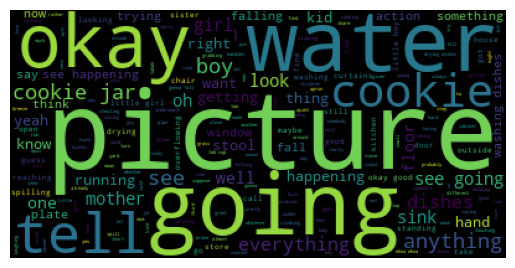

[('picture', 102), ('going', 100), ('water', 98), ('okay', 80), ('tell', 69), ('cookie', 63), ('cookie jar', 59), ('see', 58), ('boy', 57), ('anything', 56), ('everything', 52), ('dishes', 52), ('mother', 46), ('sink', 45), ('look', 44), ('see going', 42), ('girl', 41), ('oh', 41), ('one', 38), ('floor', 36), ('well', 36), ('running', 33), ('happening', 32), ('kid', 30), ('hand', 28), ('right', 27), ('know', 26), ('getting', 25), ('yeah', 24), ('want', 24), ('stool', 24), ('thing', 23), ('see happening', 23), ('trying', 22), ('fall', 22), ('something', 21), ('window', 21), ('think', 21), ('washing dishes', 21), ('falling', 20), ('say', 18), ('now', 18), ('plate', 17), ('action', 17), ('little girl', 17), ('okay good', 17), ('still', 16), ('go', 15), ('washing', 15), ('chair', 15)]


In [139]:
# see the most frequent words of AD (positive) group
ad_top_words = make_wordcloud(text for _, text in train_data["ad"])
print(ad_top_words[:50])
ad_top_words_set = set([w for w, count in ad_top_words[:200]])

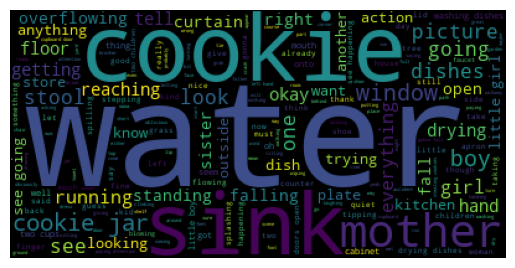

[('water', 102), ('cookie', 97), ('sink', 85), ('mother', 75), ('cookie jar', 75), ('boy', 71), ('window', 69), ('stool', 54), ('see', 53), ('picture', 53), ('going', 53), ('one', 52), ('look', 52), ('dishes', 51), ('girl', 46), ('running', 46), ('everything', 45), ('okay', 41), ('reaching', 40), ('getting', 38), ('tell', 38), ('floor', 37), ('hand', 35), ('drying', 34), ('overflowing', 33), ('right', 32), ('curtain', 31), ('standing', 30), ('open', 29), ('falling', 28), ('fall', 26), ('sister', 26), ('want', 24), ('little girl', 24), ('action', 23), ('plate', 22), ('anything', 21), ('see going', 21), ('know', 20), ('looking', 20), ('kitchen', 20), ('trying', 20), ('outside', 19), ('dish', 19), ('another', 19), ('store', 19), ('washing dishes', 18), ('onto', 17), ('thing', 17), ('little boy', 17)]


In [140]:
# see the most frequent words of CN (negative) group
cn_top_words = make_wordcloud([text for _, text in train_data["cn"]])
print(cn_top_words[:50])
cn_top_words_set = set([w for w, count in cn_top_words[:200]])

In [141]:
# observe the difference in 2 word set
ad_unique = ad_top_words_set - cn_top_words_set
cn_unique = cn_top_words_set - ad_top_words_set
print("AD unique words =\n", ad_unique)
print("----------------")
print("CN unique words =\n", cn_unique)

AD unique words =
 {'stealing', 'telling', 'pretty', 'love', 'hard', 'whoa whoa', 'slipping', 'curtains', 'spilled', 'different', 'us', 'stone', 'lady', 'break', 'whether', 'next', 'eat', 'taken', 'almost', 'made', 'home', 'grabbing', 'sorry', 'pipe', 'upset', 'try', 'shoes', 'call', 'young', 'cup', 'share', 'saucer', 'small', 'wash', 'okay good', 'handles', 'working', 'spill', 'cooking', 'always', 'put', 'find', 'fell', 'ladder', 'suppose', 'gotta', 'assume', 'neck', 'step', 'yes', 'guy', 'whatever', 'bushes', 'ha', 'lot', 'told', 'goes', 'given', 'stand', 'broke', 'rather', 'touching', 'underneath', 'watching', 'somebody', 'problem', 'third', 'two cup', 'stove', 'breeze', 'new', 'read'}
----------------
CN unique words =
 {'full', 'dried', 'giving', 'room', 'cupboard door', 'brother', 'wiping', 'place', 'splashing', 'show', 'corner', 'foot', 'crash', 'son', 'left hand', 'either', 'towel', 'obviously', 'faucet', 'attention', 'accident', 'wet', 'path', 'walking', 'tipping', 'even', 'wi

We can see that there are some words that are common in both categories (AD/CN):
- cookie, cookie jar, water, sink, look, etc

Some words that frequently appear in AD (positive) group, but not so frequently in CN (negative) groups:
- ladder, lady, stone, scaucer, somebody, whatever, guy

These words tend to be generic (not very specific)

Some words that frequently appear in CN (negative) group, but not so frequently in AD (positive) groups:
- dress, left hand, faucet, tipping

These words tend to be more specific and detailed. 

In [142]:
# combine data into a dataframe, for export to a csv for further processing
train_dict = {
    "text": [],  # the transcript
    "target": [],  # the target: positive (AD), negative (CN)
    "file": [],
}
for item in train_data["ad"]:
    train_dict["text"].append(item[1])
    train_dict["file"].append(item[0])
    train_dict["target"].append("AD")

for item in train_data["cn"]:
    train_dict["text"].append(item[1])
    train_dict["file"].append(item[0])
    train_dict["target"].append("CN")

print("Text count =", len(train_dict["text"]))
print("Target count =", len(train_dict["target"]))

Text count = 166
Target count = 166


In [143]:
train_df = pd.DataFrame(train_dict)
# merge mmse scores onto train df
train_df = train_df.merge(mmse_df, left_on="file", right_on="adressfname")[
    ["text", "target", "mmse"]
]
print(len(train_df))
train_df.head()

166


,text,target,mmse
0,The cookie jar and the little\n\n\n\nboy about...,AD,20
1,Tell me everything that's going on\n\n\n\nthe ...,AD,11
2,As a picture little girl and a little boy stan...,AD,18
3,She will find her mother worship trying to dis...,AD,18
4,What do you see going on\n\n\n\nthe boys on a ...,AD,26


In [144]:
train_df[["text", "target"]].describe()

,text,target
count,166,166
unique,166,2
top,The cookie jar and the little\n\n\n\nboy about...,AD
freq,1,87


In [145]:
train_df[["mmse"]].describe()

,mmse
count,166.000000
mean,22.933735
std,6.992754
min,3.000000
25%,17.250000
50%,26.000000
75%,29.000000
max,30.000000


We can see we have total of 166 examples, with 87 positive (AD) and 79 negative (CN). The train_set is relatively balanced. 

In [146]:
train_df.groupby("target")[["mmse"]].agg(["count", "min", "mean", "median", "max"])

mmse                          
       count min       mean median max
target                                
AD        87   3  17.436782   18.0  28
CN        79  26  28.987342   29.0  30

We also see that the MMSE, which evaluates the presence and severity of cognitive impairment, is drastically higher for the CN group than the AD group for both the median and mean, which is to be expected.

Now we can split the data into train and dev set

In [147]:
train_df, dev_df = train_test_split(train_df, test_size=0.2, random_state=42)
print("train len =", len(train_df))
print("dev len =", len(dev_df))

train len = 132
dev len = 34


In [148]:
train_df.head()

,text,target,mmse
157,Reaching for a cookie chair possibly moving to...,CN,28
2,As a picture little girl and a little boy stan...,AD,18
118,Tell me everything that you see happening. Eve...,CN,30
112,I think what I want you to do is take a look a...,CN,30
68,Tell me all the action that you can say on wha...,AD,20


In [149]:
dev_df.head()

,text,target,mmse
100,"Everything you see going on in this picture, g...",CN,28
136,"Now you just look at the picture. Okay, this i...",CN,30
78,Tell me everything that you see going on in th...,AD,20
56,Girls and boys getting her one that stores sto...,AD,20
97,"All right, we have a few more tasks to go thro...",CN,30


In [150]:
# write to csv
path = "../data/splits/"

In [151]:
print("Writing to csv files...")

train_df.to_csv(path + "train.csv", index=False)
dev_df.to_csv(path + "dev.csv", index=False)
print("Completed")

Writing to csv files...
Completed
